Exercises: 

Conceptual:

Exercise 1:

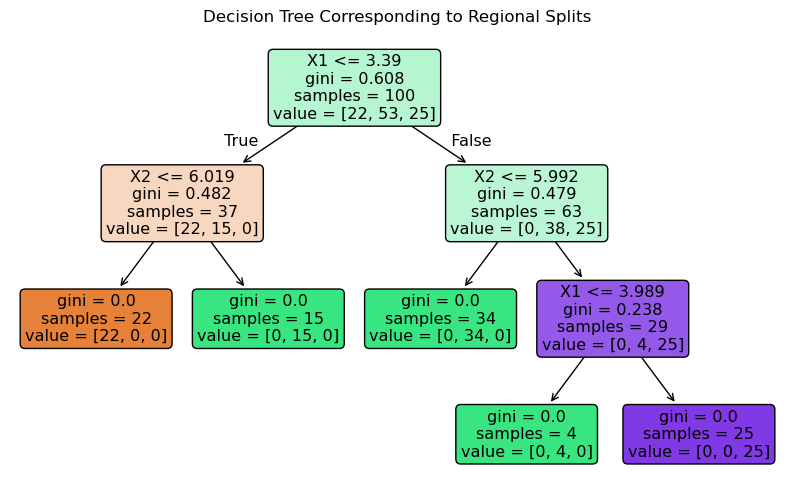

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree


np.random.seed(0)
n = 100
X1 = np.random.uniform(0, 10, size=n)
X2 = np.random.uniform(0, 10, size=n)

X_features = np.column_stack((X1, X2))
Y = (X1 > 4).astype(int) + (X2 > 6).astype(int)


tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_features, Y)

plt.figure(figsize=(10, 6))
plot_tree(
    tree_model,
    feature_names=["X1", "X2"],
    filled=True,
    rounded=True,
)
plt.title("Decision Tree Corresponding to Regional Splits")
plt.show()

Exercise 2:

Since every tree built in the sequence is restricted to being a stump, every tree's contribution depends on at most one predictor variable.

When you sum these individual univariate tree predictions together across the boosting iterations, the final model naturally takes the form of a sum of separate functions for each predictor:

$f(X) = \sum_{j=1}^p f_j(X_j)$

Exercise 3:

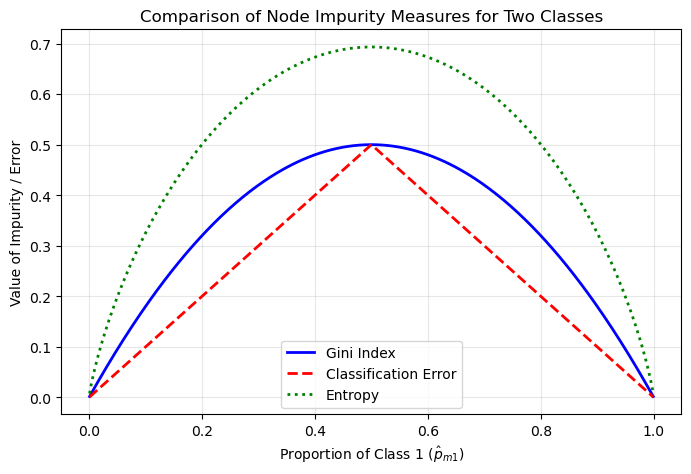

In [2]:

p1 = np.linspace(0.001, 0.999, 400)  # avoid exact 0 for log in entropy
p2 = 1 - p1


gini = 2 * p1 * p2
classification_error = 1 - np.maximum(p1, p2)
entropy = -(p1 * np.log(p1) + p2 * np.log(p2))


plt.figure(figsize=(8, 5))
plt.plot(p1, gini, label="Gini Index", color="blue", linewidth=2)
plt.plot(
    p1, classification_error, label="Classification Error", color="red", linestyle="--", linewidth=2
)
plt.plot(p1, entropy, label="Entropy", color="green", linestyle=":", linewidth=2)

plt.title("Comparison of Node Impurity Measures for Two Classes")
plt.xlabel("Proportion of Class 1 ($\hat{p}_{m1}$)")
plt.ylabel("Value of Impurity / Error")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Exercise 4:

(a) Tree Structure from the Partition Map
To trace the tree from the left-hand panel:
1. **First split ($X_1 = 1$):** 
   - If $X_1 \ge 1 \rightarrow$ Region ends with a mean of **$5$**.
   - If $X_1 < 1 \rightarrow$ Move to the next split.
2. **Second split ($X_2 = 1$):** 
   - If $X_2 \ge 1 \rightarrow$ Region ends with a mean of **$15$**.
   - If $X_2 < 1 \rightarrow$ Move to the next split.
3. **Third split ($X_1 = 0$):** 
   - If $X_1 < 0 \rightarrow$ Region ends with a mean of **$3$**.
   - If $X_1 \ge 0 \rightarrow$ Move to the final split.
4. **Fourth split ($X_2 = 0$):** 
   - If $X_2 < 0 \rightarrow$ Region ends with a mean of **$10$**.
   - If $X_2 \ge 0 \rightarrow$ Region ends with a mean of **$0$**.




(b) Partition Map from the Tree Rules
To draw the partition map from the right-hand panel:
1. **Root Node ($X_2 < 1$):** Splits the entire space horizontally at $X_2 = 1$.
2. **Left Branch ($X_2 < 1$):** 
   - Split vertically at $X_1 = 1$, creating two regions:
     - $X_1 < 1 \rightarrow$ Mean = **$-1.80$**
     - $X_1 \ge 1 \rightarrow$ Mean = **$0.63$**
3. **Right Branch ($X_2 \ge 1$):** 
   - Split horizontally at $X_2 = 2$, creating a top strip ($X_2 \ge 2$, Mean = **$2.49$**) and a middle strip ($1 \le X_2 < 2$).
   - The middle strip is further split vertically at $X_1 = 0$:
     - $X_1 < 0 \rightarrow$ Mean = **$-1.06$**
     - $X_1 \ge 0 \rightarrow$ Mean = **$0.21$**

Exercise 5:

Majority Vote (Hard Voting)

**Mechanism:** Each of the 10 trees casts a single vote for its predicted class based on whether its probability estimate exceeds $0.5$.
* **Counting Votes:** 
  * Probabilities $\le 0.5$ ($0.1, 0.15, 0.2, 0.2$): **4 trees** vote for **Green**.
  * Probabilities $> 0.5$ ($0.55, 0.6, 0.6, 0.65, 0.7, 0.75$): **6 trees** vote for **Red**.
* **Final Classification:** **Red** wins by a 6-to-4 majority.



Average Probability (Soft Voting)
**Mechanism:** We average the probability estimates directly across all 10 trees first, and then classify based on that combined average.
* **Calculation:**
  $\text{Average} = \frac{0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = \frac{4.5}{10} = 0.45$
* **Final Classification:** Since the average probability ($0.45$) is less than $0.5$, the combined model classifies the point as **Green**.


Exercise 6:


1. **Grow the Full Tree:** We start with the training data and use recursive binary splitting to grow a large, complex tree. We keep splitting until nodes hit a minimum sample size threshold.

2. **The Overfitting Trap:** Because this large tree grows too complex, it overfits the training data (low bias, massive variance).

3. **Cost-Complexity Pruning :** To fix this, we introduce a tuning parameter $\alpha$ that penalizes the tree for having too many leaves. This allows us to systematically "prune" back the weakest branches, creating a sequence of nested subtrees.

4. **Model Selection via Cross-Validation:** We use K-fold cross-validation across our training data to test different values of $\alpha$. By measuring the out-of-fold Mean Squared Error (MSE), we find the optimal $\alpha$ that gives us the best balance—reducing variance so the model generalizes well to unseen test data.